In [12]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv('../data/retail_campaign.csv')
df.head()

,customer_id,recency,history,used_discount,used_bogo,is_referral,zip_code_Rural,zip_code_Surburban,zip_code_Urban,channel_Multichannel,channel_Phone,channel_Web,discount,revenue
0,2,6,329.08,1,1,1,1,0,0,0,0,1,0,0.0
1,4,9,675.83,1,0,1,1,0,0,0,0,1,1,0.0
2,9,9,675.07,1,1,1,1,0,0,0,1,0,1,0.0
3,14,2,101.64,0,1,0,0,0,1,0,0,1,1,25.0
4,15,4,241.42,0,1,1,1,0,0,1,0,0,0,0.0


In [14]:
print(df.shape)
print('Share with the discount offer:', df.discount.mean().round(3))
print('Share who converted:', (df.revenue > 0).mean().round(4))
print('Conversion rate by group:')
print(df.groupby('discount').revenue.apply(lambda s: (s > 0).mean()).round(4))

(42613, 14)
Share with the discount offer: 0.5
Share who converted: 0.1445
Conversion rate by group:
discount
0    0.1062
1    0.1828
Name: revenue, dtype: float64


In [7]:
print(df.shape)
print('Share with the discount offer:', df.discount.mean().round(3))
print('Share who converted:', df.conversion.mean().round(4))
print('Conversion rate by group:')
print(df.groupby('discount').conversion.mean().round(4))

(64000, 10)
Share with the discount offer: 0.333
Share who converted: 0.1468
Conversion rate by group:
discount
0    0.1288
1    0.1828
Name: conversion, dtype: float64


In [15]:
features = [c for c in df.columns if c not in ('customer_id', 'discount', 'revenue')]
df.groupby('discount')[features].mean().T.round(3)

discount,0,1
recency,5.750,5.774
history,240.883,242.836
used_discount,0.553,0.551
used_bogo,0.548,0.551
is_referral,0.502,0.502
zip_code_Rural,0.147,0.152
zip_code_Surburban,0.452,0.446
zip_code_Urban,0.401,0.402
channel_Multichannel,0.122,0.121
channel_Phone,0.438,0.434


In [19]:
%pip install dowhy networkx

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 10.6 MB/s  0:00:00
   ---------------------------------------- 0.0/41.0 MB ? eta -:--:--
   -- ------------------------------------- 2.9/41.0 MB 13.9 MB/s eta 0:00:03
   ----- ---------------------------------- 5.8/41.0 MB 13.5 MB/s eta 0:00:03
   -------- ------------------------------- 8.9/41.0 MB 13.8 MB/s eta 0:00:03
   ----------- ---------------------------- 11.8/41.0 MB 13.9 MB/s eta 0:00:03
   -------------- ------------------------- 14.4/41.0 MB 13.3 MB/s eta 0:00:02
   ----------------- ---------------------- 17.6/41.0 MB 13.5 MB/s eta 0:00:02
   ------------------- -------------------- 20.2/41.0 MB 13.6 MB/s eta 0:00:02
   --------------------- ------------------ 22.3/41.0 MB 13.3 MB/s eta 0:00:02
   ----------------------- ------

In [20]:
from src.casual_graph import build_model,identify_and_estimate,naive_difference,confounder_columns
model=build_model(df)
identified,estimate=identify_and_estimate(model)
print(identified)

c:\Users\DELL\Desktop\Python Course\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
───────────(E[revenue|zip_code_Urban,is_referral,zip_code_Rural,recency,channe ↪
d[discount]                                                                    ↪

↪                                                                              ↪
↪ l_Phone,channel_Web,history,used_discount,zip_code_Surburban,used_bogo,chann ↪
↪                                                                              ↪

↪                  
↪ el_Multichannel])
↪                  
Estimand assumption 1, Unconfoundedness: If U→{discount} and U→revenue then P(revenue|discount,zip_code_Urban,is_referral,zip_code_Rural,recency,channel_Phone,channel_Web,history,used_discount,zip_code_Surburban,used_bogo,channel_Multichannel,U) = P(revenue|discount,zip_code_Urban,is_referral,zip_code_Rural,recency,channel_Phone,channel_Web,

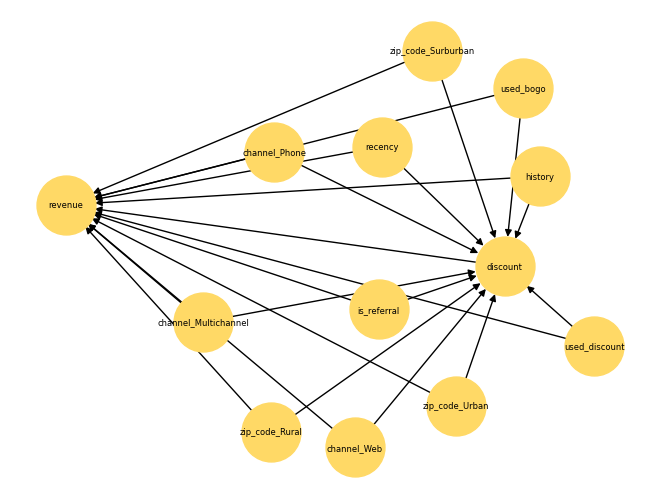

In [21]:
import networkx as nx
g=nx.DiGraph()
for c in confounder_columns(df):
    g.add_edge(c,'discount');g.add_edge(c,'revenue')
g.add_edge('discount','revenue')
nx.draw(g,with_labels=True,node_size=1800,node_color='#ffd966',font_size=6)
plt.show()

In [22]:
pd.DataFrame({
    'estimate': ['Naive difference', 'Adjusted (backdoor linear regression)'],
    'value': [naive_difference(df), float(estimate.value)]
}).round(4)

,estimate,value
0,Naive difference,1.9147
1,Adjusted (backdoor linear regression),1.9015
